# Do the gate decisions matter?

Main experiment of ours is to see the trained G1 model which computes a different gate for every layer, head, token actually use that flexibility or would a fixed scale pee head do just as well. To check this we score the identical held out tokens under three conditions

| condition | gate used at layer ℓ, head h, position t |
|---|---|
| **learned** | the gate the model computes, $\sigma(W_g x_t)$ |
| **mean** | one constant per (ℓ, h): the average learned gate on the *calibration* split |
| **shuffled** | the gate vector the model computed at the **same position** of a **different** eval story (whole head vector of the layer swapped, so the relationship between heads is kept) |


In [ ]:
import os
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

sys.path.insert(0, str(Path.cwd()))
from gated_attention_model import load_checkpoint, score_windows, pick_device, batch_windows

RUN_NAME = 'full' #os.environ.get('GA_RUN', 'smoke')
#REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'experiments').is_dir())
DATA_DIR = Path('../../processed_data/gated_attention')
CKPT_DIR = Path('../../checkpoints/gated_attention')
RESULTS_DIR = Path('../../results/gated_attention')
device = pick_device()

meta = json.loads((DATA_DIR / 'meta.json').read_text())
train_cfg = json.loads((RESULTS_DIR / 'train_config.json').read_text())
SEEDS = train_cfg['seeds']
PAD_ID = meta['pad_id']
N_SHUFFLES = 3

calib_windows = pd.read_parquet(DATA_DIR / 'calib_windows.parquet').to_dict('records')
eval_windows = pd.read_parquet(DATA_DIR / 'eval_windows.parquet').to_dict('records')
print('run:', RUN_NAME, '| seeds:', SEEDS, '| calib windows', len(calib_windows), '| eval windows', len(eval_windows))

run: full | seeds: [0, 1, 2] | calib windows 1873 | eval windows 4898


## Mean gate per layer and head (calibration split)

The mean is taken over every real input position of the calibration stories (padding is never included; positions that appear in two overlapping windows are counted once, in the window that scores them).

In [2]:
def calibration_means(model):
    _, gates = score_windows(model, calib_windows, PAD_ID, device, keep_gates=True)
    total, count = 0.0, 0
    for w, g in zip(calib_windows, gates):              # g: [L, T, H]
        real = g[:, w['score_from']:, :].astype(np.float64)
        total = total + real.sum(axis=1)
        count += real.shape[1]
    return total / count, gates                           # [L, H], per-window calibration gates

## Shuffled gates

For each recipient window we pick a donor window from a **different story**, with the same kind of start (a story's first window, which begins with EOS, or a later sliding window) and at least as many positions. The donor's learned gates at positions 0..T−1 replace the recipient's gates at the same positions, in every layer, with the whole head vector kept together. The recipient's own tokens and targets do not change. We repeat with `N_SHUFFLES` reproducible donor assignments and report coverage (fraction of recipient targets that received donor gates).

In [3]:
def donor_assignment(windows, seed):
    rng = np.random.default_rng(seed)
    lengths = np.array([len(w['tokens']) - 1 for w in windows])
    first = np.array([w['offset'] == 0 for w in windows])
    stories = np.array([w['story_id'] for w in windows])
    donors, covered, total = np.empty(len(windows), dtype=int), 0, 0
    for i, w in enumerate(windows):
        ok = np.nonzero((stories != w['story_id']) & (first == first[i]) & (lengths >= lengths[i]))[0]
        if len(ok) == 0:                                   # fall back to the longest other-story window
            ok = np.nonzero(stories != w['story_id'])[0]
            ok = ok[lengths[ok] == lengths[ok].max()]
        donors[i] = rng.choice(ok)
        n_scored = lengths[i] - w['score_from']
        covered += max(0, min(lengths[donors[i]], lengths[i]) - w['score_from'])
        total += n_scored
    return donors, covered / total


def shuffled_override_fn(learned_gates, donors, n_layer):
    def fn(idx, T):
        out = {}
        for l in range(n_layer):
            g = torch.ones(len(idx), T, learned_gates[0].shape[-1])
            for b, i in enumerate(idx):
                d = learned_gates[donors[i]][l]           # [T_donor, H]
                n = min(T, d.shape[0])
                g[b, :n] = torch.from_numpy(d[:n].astype(np.float32))
            out[l] = g.to(device)
        return out
    return fn

## Run all conditions for every G1 seed

In [4]:
all_rows, gate_means, coverage, learned_gate_samples, calib_gates_by_seed = [], {}, [], {}, {}
for seed in SEEDS:
    model, ck = load_checkpoint(CKPT_DIR / f'g1_seed{seed}' / 'best.pt', device)
    n_layer = model.n_layer
    means, calib_gates = calibration_means(model)
    gate_means[seed] = means
    calib_gates_by_seed[seed] = calib_gates
    mean_fn = lambda idx, T, m=torch.tensor(means, dtype=torch.float32, device=device): {l: m[l] for l in range(n_layer)}

    rows, learned_gates = score_windows(model, eval_windows, PAD_ID, device, keep_gates=True)
    all_rows.append(pd.DataFrame(rows).assign(seed=seed, condition='learned'))
    learned_gate_samples[seed] = np.concatenate([g[:, w['score_from']:, :] for w, g in zip(eval_windows, learned_gates)], axis=1)

    rows, _ = score_windows(model, eval_windows, PAD_ID, device, gate_override_fn=mean_fn)
    all_rows.append(pd.DataFrame(rows).assign(seed=seed, condition='mean'))

    for k in range(N_SHUFFLES):
        donors, cov = donor_assignment(eval_windows, seed=100 * seed + k)
        assert all(eval_windows[d]['story_id'] != w['story_id'] for d, w in zip(donors, eval_windows))  # no self-donors
        coverage.append(dict(seed=seed, shuffle=k, coverage=cov))
        rows, _ = score_windows(model, eval_windows, PAD_ID, device,
                                gate_override_fn=shuffled_override_fn(learned_gates, donors, n_layer))
        all_rows.append(pd.DataFrame(rows).assign(seed=seed, condition=f'shuffled_{k}'))
    print(f'seed {seed}: done')

g1_losses = pd.concat(all_rows, ignore_index=True)
g1_losses.to_parquet(RESULTS_DIR / 'g1_intervention_token_losses.parquet', index=False)
np.save(RESULTS_DIR / 'g1_calibration_gate_means.npy', np.stack([gate_means[s] for s in SEEDS]))
pd.DataFrame(coverage)

seed 0: done


seed 1: done


seed 2: done


,seed,shuffle,coverage
0,0,0,1.0
1,0,1,1.0
2,0,2,1.0
3,1,0,1.0
4,1,1,1.0
5,1,2,1.0
6,2,0,1.0
7,2,1,1.0
8,2,2,1.0


**Consistency check:** the learned-gate losses here must equal the G1 losses saved by notebook 02 (same checkpoint, same tokens).

In [5]:
nb02 = pd.read_parquet(RESULTS_DIR / 'eval_token_losses.parquet')
for seed in SEEDS:
    a = nb02[(nb02.variant == 'g1') & (nb02.seed == seed)].sort_values(['story_id', 'target_pos'])
    b = g1_losses[(g1_losses.condition == 'learned') & (g1_losses.seed == seed)].sort_values(['story_id', 'target_pos'])
    assert (a.target_pos.values == b.target_pos.values).all()
    print(f'seed {seed}: max |loss diff| vs notebook 02 = {np.abs(a.loss.values - b.loss.values).max():.2e}')

seed 0: max |loss diff| vs notebook 02 = 0.00e+00


seed 1: max |loss diff| vs notebook 02 = 0.00e+00


seed 2: max |loss diff| vs notebook 02 = 0.00e+00


## Results: loss under each gate condition

Loss is the mean next-token loss over all eval targets (nats); perplexity = exp(mean loss). `Δ vs learned` is paired on identical tokens (positive = worse than the model's own gates), with a 95% interval from resampling whole stories. The baseline of the same paired seed is included for reference. Shuffled rows average the per-token losses over the `N_SHUFFLES` donor assignments.

In [6]:
def story_bootstrap(diff_df, n_boot=2000, seed=0):
    per_story = diff_df.groupby('story_id')['diff'].agg(['sum', 'size'])
    sums, sizes = per_story['sum'].to_numpy(), per_story['size'].to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(sums), size=(n_boot, len(sums)))
    boots = sums[idx].sum(1) / sizes[idx].sum(1)
    return sums.sum() / sizes.sum(), np.percentile(boots, 2.5), np.percentile(boots, 97.5)


wide = g1_losses.pivot_table(index=['seed', 'story_id', 'target_pos'], columns='condition', values='loss').reset_index()
wide['shuffled'] = wide[[f'shuffled_{k}' for k in range(N_SHUFFLES)]].mean(axis=1)
base = nb02[nb02.variant == 'baseline'].rename(columns={'loss': 'baseline'})[['seed', 'story_id', 'target_pos', 'baseline']]
wide = wide.merge(base, on=['seed', 'story_id', 'target_pos'], validate='one_to_one')
wide.to_parquet(RESULTS_DIR / 'g1_intervention_wide.parquet', index=False)

rows = []
for seed in SEEDS:
    d = wide[wide.seed == seed]
    for cond in ['learned', 'mean', 'shuffled'] + [f'shuffled_{k}' for k in range(N_SHUFFLES)] + ['baseline']:
        r = dict(seed=seed, condition=cond, loss=d[cond].mean(), ppl=np.exp(d[cond].mean()))
        if cond != 'learned':
            r['delta_vs_learned'], r['ci_low'], r['ci_high'] = story_bootstrap(
                pd.DataFrame({'story_id': d.story_id, 'diff': d[cond] - d['learned']}))
        rows.append(r)
override_table = pd.DataFrame(rows)
override_table.to_csv(RESULTS_DIR / 'gate_override_table.csv', index=False)
override_table[~override_table.condition.str.startswith('shuffled_')].round(4)

,seed,condition,loss,ppl,delta_vs_learned,ci_low,ci_high
0,0,learned,2.0765,7.9768,NaN,NaN,NaN
1,0,mean,2.3283,10.2607,0.2518,0.2497,0.2538
2,0,shuffled,2.4999,12.1814,0.4234,0.4206,0.4261
6,0,baseline,2.0865,8.0563,0.0099,0.0084,0.0114
7,1,learned,2.0872,8.0626,NaN,NaN,NaN
8,1,mean,2.3987,11.0091,0.3115,0.3091,0.3139
9,1,shuffled,2.6165,13.6876,0.5293,0.5258,0.5328
13,1,baseline,2.0911,8.0937,0.0038,0.0023,0.0054
14,2,learned,2.0699,7.9237,NaN,NaN,NaN
15,2,mean,2.3629,10.6215,0.2930,0.2907,0.2954


In [7]:
# individual shuffles (spread across donor assignments)
override_table[override_table.condition.str.startswith('shuffled_')].round(4)

,seed,condition,loss,ppl,delta_vs_learned,ci_low,ci_high
3,0,shuffled_0,2.5005,12.1890,0.4240,0.4209,0.4270
4,0,shuffled_1,2.4995,12.1768,0.4230,0.4200,0.4259
5,0,shuffled_2,2.4997,12.1784,0.4231,0.4200,0.4262
10,1,shuffled_0,2.6185,13.7151,0.5313,0.5271,0.5355
11,1,shuffled_1,2.6144,13.6597,0.5272,0.5233,0.5314
12,1,shuffled_2,2.6165,13.6882,0.5293,0.5252,0.5336
17,2,shuffled_0,2.4678,11.7966,0.3980,0.3950,0.4011
18,2,shuffled_1,2.4681,11.8000,0.3982,0.3954,0.4012
19,2,shuffled_2,2.4692,11.8131,0.3994,0.3964,0.4023


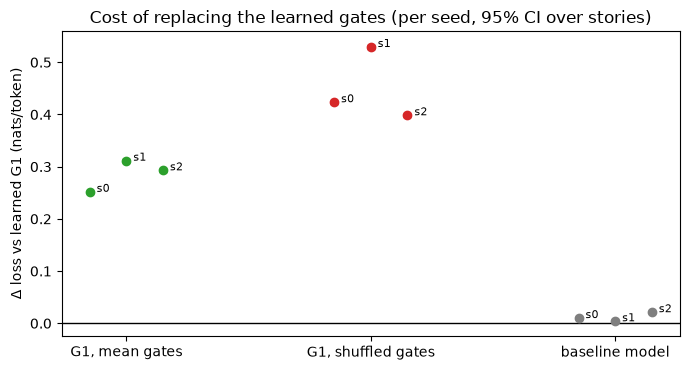

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.8))
conds = [('mean', 'tab:green'), ('shuffled', 'tab:red'), ('baseline', 'tab:gray')]
for i, (cond, c) in enumerate(conds):
    d = override_table[override_table.condition == cond]
    for j, r in enumerate(d.itertuples()):
        x = i + (j - (len(d) - 1) / 2) * 0.15
        ax.errorbar(x, r.delta_vs_learned, yerr=[[r.delta_vs_learned - r.ci_low], [r.ci_high - r.delta_vs_learned]],
                    fmt='o', color=c, capsize=3)
        ax.annotate(f's{r.seed}', (x, r.delta_vs_learned), textcoords='offset points', xytext=(5, 0), fontsize=8)
ax.axhline(0, color='k', lw=1)
ax.set_xticks(range(len(conds)), ['G1, mean gates', 'G1, shuffled gates', 'baseline model'])
ax.set_ylabel('Δ loss vs learned G1 (nats/token)')
ax.set_title('Cost of replacing the learned gates (per seed, 95% CI over stories)')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig_gate_overrides.png', dpi=150)
plt.show()

## Extra: what do the gates depend on?

The mean condition removes *all* input dependence at once. Three finer replacements, all estimated on the calibration split and applied to the same eval tokens, show which kind of information the gates carry:

- **token mean**: the average gate of each (layer, head) for each *input token id* (tokens never seen in calibration fall back to the layer mean). Keeps "which word am I at", drops the context.
- **position mean**: the average gate of each (layer, head) at each *position in the window*. Keeps "where am I", drops the content.
- **one layer → mean**: only one layer's gates are replaced by their means; the others stay learned. Shows which layers' gate decisions matter most.

If the token mean recovers most of the gap between mean and learned, the gates are mostly a function of the current token; if not, they depend on the context.

In [9]:
def lookup_means(seed, n_layer, n_head, vocab_size, block_size):
    tok_sum = np.zeros((n_layer, vocab_size, n_head)); tok_n = np.zeros(vocab_size)
    pos_sum = np.zeros((n_layer, block_size, n_head)); pos_n = np.zeros(block_size)
    for w, g in zip(calib_windows, calib_gates_by_seed[seed]):
        s0 = w['score_from']
        ids = np.asarray(w['tokens'][:-1])[s0:]
        gg = g[:, s0:, :].astype(np.float64)                     # [L, n, H]
        for l in range(n_layer):
            np.add.at(tok_sum[l], ids, gg[l])
        np.add.at(tok_n, ids, 1)
        pos = np.arange(s0, s0 + gg.shape[1])
        pos_sum[:, pos] += gg
        pos_n[pos] += 1
    layer_mean = gate_means[seed][:, None, :]
    tok_mean = np.where(tok_n[None, :, None] > 0, tok_sum / np.maximum(tok_n, 1)[None, :, None], layer_mean)
    pos_mean = np.where(pos_n[None, :, None] > 0, pos_sum / np.maximum(pos_n, 1)[None, :, None], layer_mean)
    return (torch.tensor(tok_mean, dtype=torch.float32, device=device),
            torch.tensor(pos_mean, dtype=torch.float32, device=device), tok_n)


extra_rows = []
for seed in SEEDS:
    model, _ = load_checkpoint(CKPT_DIR / f'g1_seed{seed}' / 'best.pt', device)
    L_, H_ = model.n_layer, model.n_head
    tok_mean, pos_mean, tok_n = lookup_means(seed, L_, H_, meta['vocab_size'], meta['block_size'])
    m = torch.tensor(gate_means[seed], dtype=torch.float32, device=device)

    def token_fn(idx, T):
        x, _ = batch_windows(eval_windows, idx, PAD_ID)
        x = x.to(device)
        return {l: tok_mean[l][x] for l in range(L_)}             # [B, T, H]

    def position_fn(idx, T):
        return {l: pos_mean[l][:T].unsqueeze(0) for l in range(L_)}

    conds = [('token mean', token_fn), ('position mean', position_fn)]
    conds += [(f'layer {l} → mean', (lambda l: lambda idx, T: {l: m[l]})(l)) for l in range(L_)]
    learned = wide[wide.seed == seed].set_index(['story_id', 'target_pos'])['learned']
    for name, fn in conds:
        rows_, _ = score_windows(model, eval_windows, PAD_ID, device, gate_override_fn=fn)
        d = pd.DataFrame(rows_).set_index(['story_id', 'target_pos'])['loss'].reindex(learned.index)
        delta, lo, hi = story_bootstrap(pd.DataFrame({'story_id': learned.index.get_level_values(0),
                                                      'diff': d.values - learned.values}))
        extra_rows.append(dict(seed=seed, condition=name, loss=d.mean(), delta_vs_learned=delta, ci_low=lo, ci_high=hi))
    print(f'seed {seed}: calibration covers {(tok_n > 0).mean():.1%} of the vocabulary')
gate_extras = pd.DataFrame(extra_rows)
# add the two main conditions for comparison
gate_extras = pd.concat([gate_extras, override_table[override_table.condition.isin(['mean', 'shuffled'])][gate_extras.columns]])
gate_extras.to_csv(RESULTS_DIR / 'gate_override_extras.csv', index=False)
gate_extras.pivot_table(index='condition', columns='seed', values='delta_vs_learned').round(4)

seed 0: calibration covers 87.0% of the vocabulary


seed 1: calibration covers 87.0% of the vocabulary


seed 2: calibration covers 87.0% of the vocabulary


seed,0,1,2
condition,,,
layer 0 → mean,0.1380,0.1824,0.1022
layer 1 → mean,0.0158,0.0217,0.0903
layer 2 → mean,0.0262,0.0234,0.0192
layer 3 → mean,0.0236,0.0247,0.0381
mean,0.2518,0.3115,0.2930
position mean,0.1983,0.2562,0.2028
shuffled,0.4234,0.5293,0.3985
token mean,0.0412,0.0829,0.2092


## Descriptive: what do the learned gates look like?

Histogram of learned gate values on the eval split (all scored positions), per layer, for the first seed, and per-head mean / spread. Qiu et al. report that useful gates are *sparse* (many values near 0). These plots describe the gates; the intervention results above are the evidence that they matter.

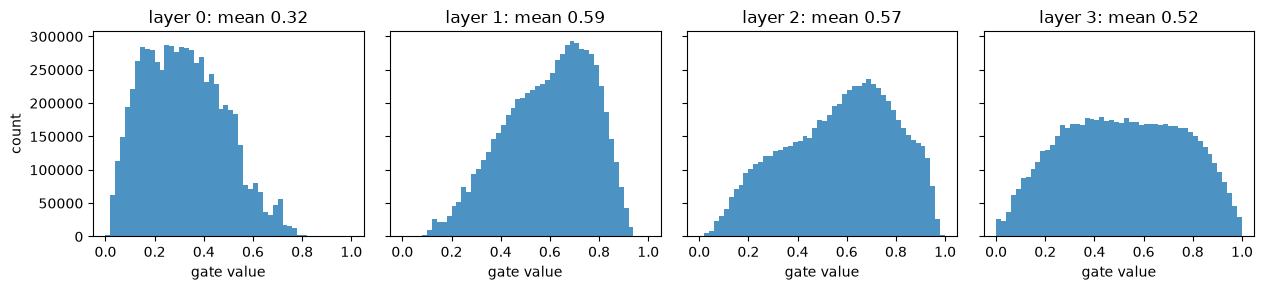

mean    std  frac_below_0_1
seed layer                              
0    0      0.321  0.143           0.078
     1      0.593  0.145           0.000
     2      0.572  0.198           0.010
     3      0.516  0.217           0.033
1    0      0.308  0.147           0.096
     1      0.648  0.157           0.003
     2      0.585  0.166           0.001
     3      0.506  0.213           0.047
2    0      0.295  0.153           0.133
     1      0.611  0.167           0.002
     2      0.612  0.176           0.002
     3      0.569  0.204           0.023

In [10]:
seed0 = SEEDS[0]
G = learned_gate_samples[seed0].astype(np.float32)          # [L, N, H]
L, N, H = G.shape
fig, axes = plt.subplots(1, L, figsize=(3.2 * L, 3), sharey=True)
for l in range(L):
    axes[l].hist(G[l].ravel(), bins=50, range=(0, 1), color='tab:blue', alpha=.8)
    axes[l].set_title(f'layer {l}: mean {G[l].mean():.2f}')
    axes[l].set_xlabel('gate value')
axes[0].set_ylabel('count')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig_gate_histograms.png', dpi=150)
plt.show()

gate_stats = pd.DataFrame([dict(seed=s, layer=l, head=h,
                                mean=learned_gate_samples[s][l, :, h].astype(np.float32).mean(),
                                std=learned_gate_samples[s][l, :, h].astype(np.float32).std(),
                                frac_below_0_1=(learned_gate_samples[s][l, :, h] < 0.1).mean(),
                                calib_mean=gate_means[s][l, h])
                           for s in SEEDS for l in range(L) for h in range(H)])
gate_stats.to_csv(RESULTS_DIR / 'gate_stats.csv', index=False)
gate_stats.groupby(['seed', 'layer'])[['mean', 'std', 'frac_below_0_1']].mean().round(3)

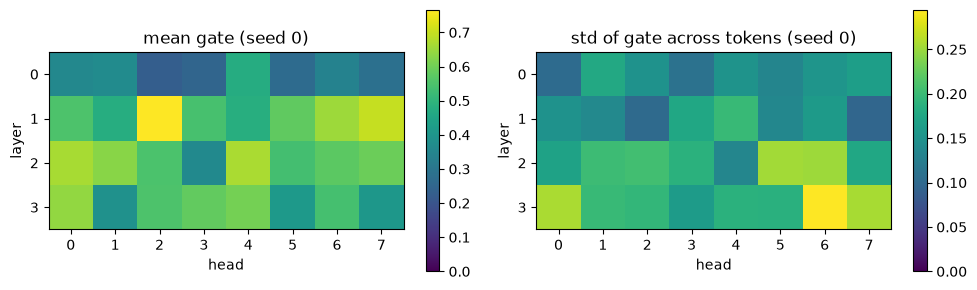

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, col, title in [(axes[0], 'mean', 'mean gate'), (axes[1], 'std', 'std of gate across tokens')]:
    m = gate_stats[gate_stats.seed == seed0].pivot(index='layer', columns='head', values=col)
    im = ax.imshow(m.values, cmap='viridis', vmin=0)
    ax.set_xlabel('head'); ax.set_ylabel('layer'); ax.set_title(f'{title} (seed {seed0})')
    plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## Extra: attention sinks in the three variants

Both mechanisms let a head do "less". Without them, a softmax head that has nothing useful to read must still put its weight somewhere, and trained models often dump it on the first token (an *attention sink*). Here we measure, for queries at positions ≥ 16 of first windows (which start with EOS at position 0):
- the average attention weight on position 0 (the EOS), per layer;
- for the sink model, the average mass on the phantom sink option.

If G1 and sink reduce the attention placed on position 0, they are providing a cheaper way to abstain.

In [12]:
first_windows = [w for w in eval_windows if w['offset'] == 0 and len(w['tokens']) - 1 >= 64][:200]
sink_rows = []
for seed in SEEDS:
    for variant in ['baseline', 'g1', 'sink']:
        model, _ = load_checkpoint(CKPT_DIR / f'{variant}_seed{seed}' / 'best.pt', device)
        acc = np.zeros((model.n_layer, 2))
        for start in range(0, len(first_windows), 16):
            x, y = batch_windows(first_windows, range(start, min(start + 16, len(first_windows))), PAD_ID)
            real = (y[:, 16:] != -100).to(device)                       # real query positions >= 16
            with torch.no_grad():
                _, info = model(x.to(device), return_attn=True)
            for l, ex in enumerate(info['extras']):
                first_tok = ex['attn'][:, :, 16:, 0]                     # [B, H, T-16]
                m = real.unsqueeze(1).expand_as(first_tok)
                acc[l, 0] += first_tok[m].sum().item() / model.n_head
                acc[l, 1] += m.sum().item() / model.n_head
                if 'sink_mass' in ex:
                    sink_rows.append(dict(seed=seed, variant='sink (phantom)', layer=l,
                                          value=ex['sink_mass'][:, :, 16:][m].mean().item()))
        for l in range(model.n_layer):
            sink_rows.append(dict(seed=seed, variant=variant, layer=l, value=acc[l, 0] / acc[l, 1]))
sink_table = (pd.DataFrame(sink_rows).groupby(['variant', 'layer', 'seed']).value.mean()
              .unstack('layer').round(3))
sink_table.to_csv(RESULTS_DIR / 'attention_sink_table.csv')
sink_table

layer                    0      1      2      3
variant        seed                            
baseline       0     0.009  0.010  0.005  0.012
               1     0.018  0.017  0.003  0.006
               2     0.010  0.010  0.004  0.010
g1             0     0.014  0.009  0.004  0.008
               1     0.019  0.007  0.005  0.005
               2     0.010  0.008  0.002  0.012
sink           0     0.012  0.011  0.006  0.018
               1     0.020  0.010  0.012  0.018
               2     0.012  0.011  0.004  0.018
sink (phantom) 0     0.030  0.025  0.019  0.024
               1     0.031  0.029  0.013  0.027
               2     0.036  0.022  0.012  0.036

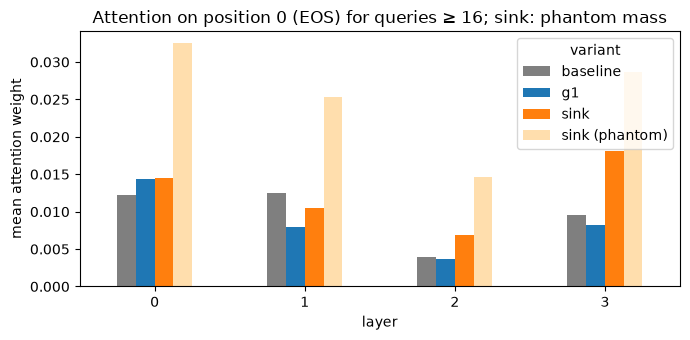

In [13]:
st = pd.DataFrame(sink_rows).groupby(['variant', 'layer']).value.mean().unstack('variant')
st.plot(kind='bar', figsize=(7, 3.5), color={'baseline': 'tab:gray', 'g1': 'tab:blue', 'sink': 'tab:orange',
                                               'sink (phantom)': 'navajowhite'})
plt.ylabel('mean attention weight')
plt.title('Attention on position 0 (EOS) for queries ≥ 16; sink: phantom mass')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig_attention_sinks.png', dpi=150)
plt.show()